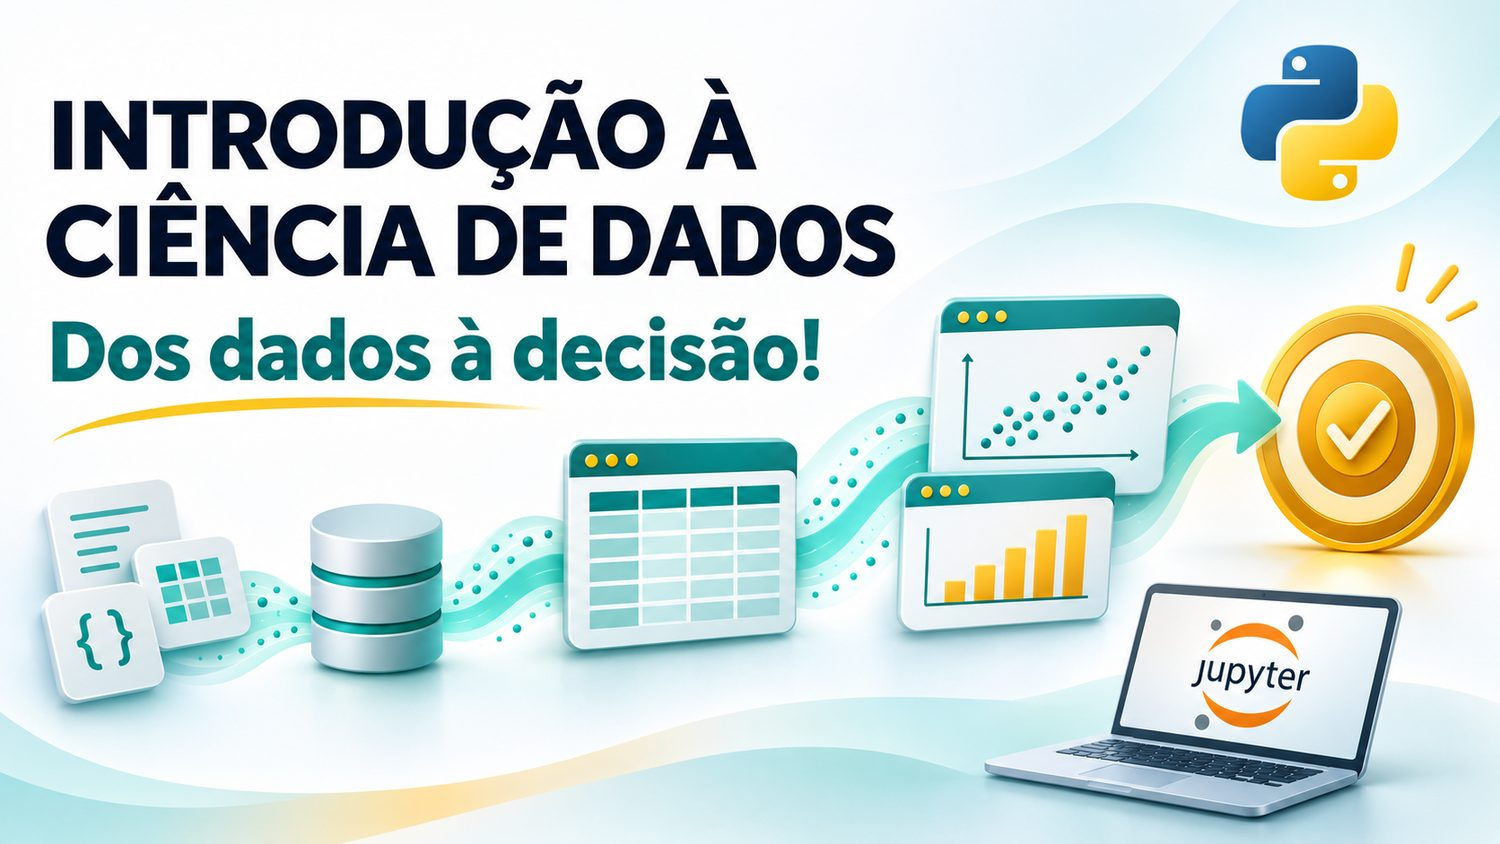

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ricardoluizdasilva/mestrado_ai_estudos/blob/main/Introdu%C3%A7%C3%A3o%20%C3%A0%20Ci%C3%AAncia%20de%20Dados/tutorial_ciencia_dados/modulo_3_explorar_os_dados/06_Series_Temporais.ipynb)

# Capítulo 6 – Séries temporais

Quando os dados têm uma ordem no tempo, essa ordem é informação. O consumo de hoje parece-se com o de ontem e com o de há uma semana, e isso muda a forma de explorar, de resumir e de testar. Este capítulo apresenta as ferramentas básicas para séries temporais e os cuidados que elas exigem.

> **Objetivos:** trabalhar com um índice de datas; reamostrar uma série para outra frequência; alisar com médias móveis; separar tendência, sazonalidade e resto; medir e interpretar a autocorrelação; calcular variações absolutas e percentuais; construir previsões de referência e avaliá-las respeitando a ordem do tempo.

**Pré-requisitos:** capítulos 1 a 5 deste módulo.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyArrowPatch, FancyBboxPatch

# Cores usadas em todo o tutorial (sempre com o mesmo significado)
AZUL, VERDE, VIOLETA, LARANJA = "#2a78d6", "#1baf7a", "#6250d6", "#eb6834"
BOM, MAU, AVISO, CINZA, TINTA = "#0ca30c", "#d03b3b", "#fab219", "#b4bdc8", "#131c26"

plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold",
                     "axes.titlelocation": "left"})


def tela(largura, altura, tamanho=(10, 3)):
    """Cria uma figura vazia, sem eixos, para desenhar esquemas."""
    fig, ax = plt.subplots(figsize=tamanho)
    ax.set_xlim(0, largura)
    ax.set_ylim(0, altura)
    ax.axis("off")
    return fig, ax


def caixa(ax, x, y, largura, altura, texto, cor, tamanho=10, negrito=False):
    """Desenha uma caixa arredondada com texto centrado."""
    ax.add_patch(FancyBboxPatch((x, y), largura, altura, boxstyle="round,pad=0.02,rounding_size=0.1",
                                fc=cor + "30", ec=cor, lw=1.6))
    ax.text(x + largura / 2, y + altura / 2, texto, ha="center", va="center", color=TINTA,
            fontsize=tamanho, linespacing=1.45, fontweight="bold" if negrito else "normal")


def seta(ax, inicio, fim, cor="#465463", **opcoes):
    """Desenha uma seta entre dois pontos."""
    opcoes.setdefault("arrowstyle", "-|>")
    ax.add_patch(FancyArrowPatch(inicio, fim, mutation_scale=14, color=cor, lw=1.5, **opcoes))

In [2]:
def gerar_escolas(semente=11):
    """Gera o consumo diário de eletricidade de 30 escolas fictícias durante um ano letivo (dados sintéticos)."""
    rng = np.random.default_rng(semente)
    n = 30
    tipo = rng.choice(["básica", "secundária"], n, p=[0.6, 0.4])
    alunos = np.where(tipo == "básica", rng.integers(120, 520, n), rng.integers(450, 1400, n))
    escolas = pd.DataFrame({
        "escola_id": [f"E{i:02d}" for i in range(1, n + 1)],
        "tipo": tipo,
        "alunos": alunos,
        "area_m2": (alunos * rng.normal(9.0, 1.2, n)).round(-1).astype(int),
        "ano_construcao": rng.integers(1965, 2016, n),
        "paineis_solares": rng.random(n) < 0.3})
    dias = pd.date_range("2025-09-01", "2026-08-31", freq="D")
    dia_do_ano = dias.dayofyear.to_numpy()
    temperatura = 16.5 + 7.5 * np.cos(2 * np.pi * (dia_do_ano - 205) / 365) + rng.normal(0, 2.2, len(dias))
    ferias = (((dias >= "2025-12-20") & (dias <= "2026-01-04")) | ((dias >= "2026-03-28") & (dias <= "2026-04-12"))
              | (dias >= "2026-07-01"))
    meteo = pd.DataFrame({"data": dias, "temperatura": temperatura.round(1), "ferias": ferias})
    tabelas = []
    for e in escolas.itertuples():
        base = 0.55 * e.alunos + 0.012 * e.area_m2 * (1.25 if e.ano_construcao < 1990 else 1.0)
        aquecimento = 1 + 0.045 * np.clip(15 - temperatura, 0, None)
        ocupacao = np.where(dias.dayofweek >= 5, 0.22, 1.0) * np.where(ferias, 0.30, 1.0)
        sol = np.clip(0.5 + 0.5 * np.cos(2 * np.pi * (dia_do_ano - 172) / 365), 0, 1)
        solar = 1 - (0.28 * sol if e.paineis_solares else 0)
        kwh = base * aquecimento * np.maximum(ocupacao, 0.08) * solar * rng.lognormal(0, 0.10, len(dias))
        avarias = rng.random(len(dias)) < 0.004                     # dias com um consumo anormal
        kwh = np.where(avarias, kwh * rng.uniform(2.5, 4.0, len(dias)), kwh)
        tabelas.append(pd.DataFrame({"escola_id": e.escola_id, "data": dias, "kwh": kwh.round(1)}))
    return escolas, pd.concat(tabelas, ignore_index=True), meteo


escolas, consumo, meteo = gerar_escolas()
consumo.head()

,escola_id,data,kwh
0,E01,2025-09-01,300.5
1,E01,2025-09-02,264.6
2,E01,2025-09-03,265.0
3,E01,2025-09-04,270.0
4,E01,2025-09-05,303.9


## Uma série temporal

Uma **série temporal** é uma sequência de valores da mesma variável, medidos em momentos sucessivos e a intervalos regulares. Vamos somar o consumo das 30 escolas em cada dia, para obter a série do município.

data
2025-09-01    9.1216
2025-09-02    9.3243
2025-09-03    9.1626
Name: mwh, dtype: float64 

Frequência: D | de 2025-09-01 a 2026-08-31


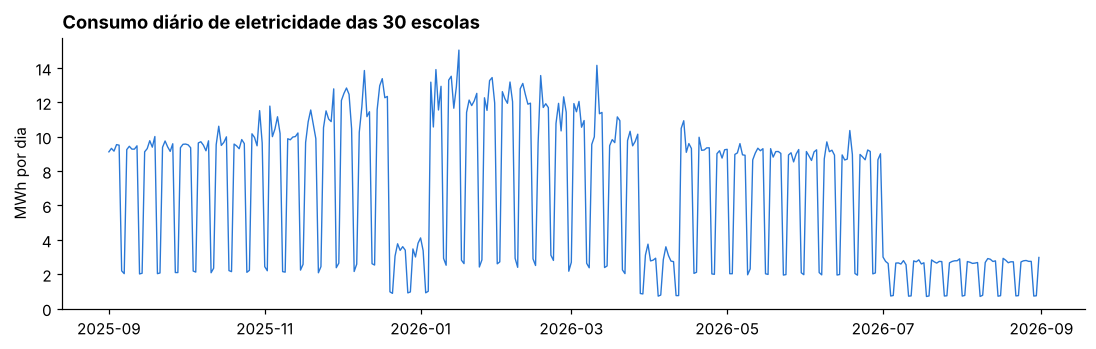

In [3]:
serie = consumo.groupby("data")["kwh"].sum() / 1000          # MWh por dia; o índice é a data
serie.name = "mwh"
print(serie.head(3), "\n")
print("Frequência:", pd.infer_freq(serie.index), "| de", serie.index.min().date(), "a", serie.index.max().date())

fig, ax = plt.subplots(figsize=(12, 3.2))
ax.plot(serie.index, serie, color=AZUL, lw=0.9)
ax.set_ylabel("MWh por dia")
ax.set_title("Consumo diário de eletricidade das 30 escolas")
plt.show()

Com a data como índice, o pandas sabe selecionar períodos pelo nome.

In [4]:
print("Um dia:        ", round(serie.loc["2026-01-15"], 2))
print("Um mês inteiro:", len(serie.loc["2026-01"]), "dias, média", round(serie.loc["2026-01"].mean(), 2))
print("Um intervalo:  ", len(serie.loc["2025-12-20":"2026-01-04"]), "dias de férias do Natal")

Um dia:         12.91
Um mês inteiro: 31 dias, média 9.01
Um intervalo:   16 dias de férias do Natal


O gráfico diário parece um pente: de cinco em cinco dias, o consumo cai. É o fim de semana. Para ver o que se passa ao longo do ano é preciso olhar para a série a outras escalas.

## Reamostrar e alisar

**Reamostrar** é mudar a frequência da série: de dias para semanas ou meses, agregando.

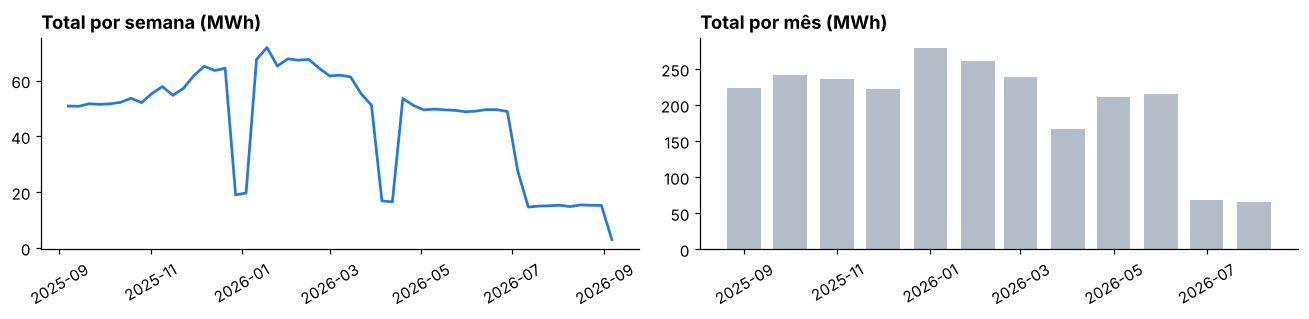

In [5]:
semanal = serie.resample("W").sum()
mensal = serie.resample("MS").sum()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3))
ax1.plot(semanal.index, semanal, color=AZUL, lw=1.8)
ax1.set_title("Total por semana (MWh)")
ax2.bar(mensal.index, mensal, width=22, color=CINZA)
ax2.set_title("Total por mês (MWh)")
for ax in (ax1, ax2):
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

Cada agregação mostra uma coisa e esconde outra. A série semanal apaga o padrão do fim de semana e deixa ver as férias. A mensal é a mais fácil de ler e já não mostra as duas semanas do Natal nem as da Páscoa.

A **média móvel** alisa sem mudar a frequência: cada dia é substituído pela média de uma janela de dias à sua volta.

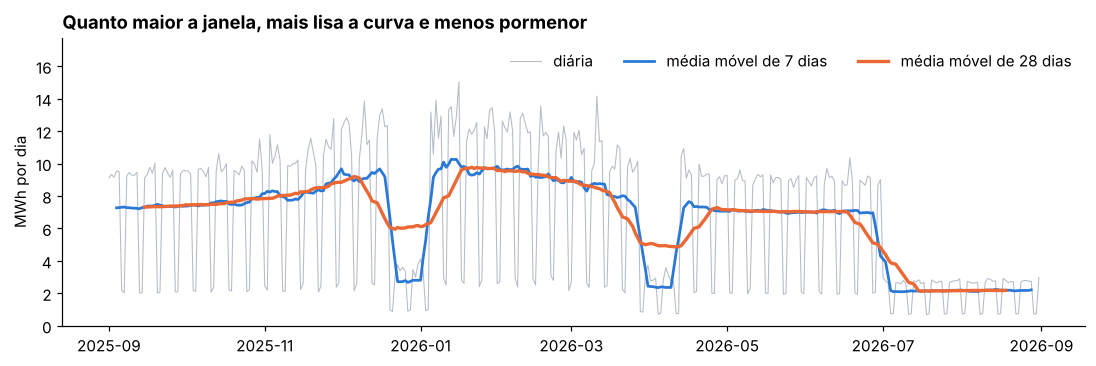

In [6]:
movel_7 = serie.rolling(7, center=True).mean()
movel_28 = serie.rolling(28, center=True).mean()

fig, ax = plt.subplots(figsize=(12, 3.4))
ax.plot(serie.index, serie, color=CINZA, lw=0.7, label="diária")
ax.plot(movel_7.index, movel_7, color=AZUL, lw=1.8, label="média móvel de 7 dias")
ax.plot(movel_28.index, movel_28, color=LARANJA, lw=2.2, label="média móvel de 28 dias")
ax.legend(frameon=False, ncol=3, loc="upper right")
ax.set_ylim(0, serie.max() * 1.18)
ax.set_ylabel("MWh por dia")
ax.set_title("Quanto maior a janela, mais lisa a curva e menos pormenor")
plt.show()

Uma janela de **7 dias** é a escolha natural aqui: tem sempre exatamente uma segunda, uma terça… e um domingo, por isso o efeito do dia da semana anula-se. A janela de 28 dias mostra só o movimento lento ao longo do ano, e arredonda as quebras das férias.

Há duas formas de posicionar a janela:

| Janela | Usa | Serve para |
| --- | --- | --- |
| **Centrada** (`center=True`) | Dias antes **e depois** | Descrever o passado |
| **Para trás** (por omissão) | Só o dia e os anteriores | Qualquer coisa que vá ser usada para prever |

Uma média centrada usa dias do futuro. Para descrever, não faz mal. Num modelo de previsão, é uma fuga de informação (módulo 1, capítulo 2).

## Tendência, sazonalidade e resto

É útil pensar numa série como a combinação de três partes.

| Componente | O que é | Nesta série |
| --- | --- | --- |
| **Tendência** | O movimento lento, de fundo | O frio do inverno, as férias |
| **Sazonalidade** | Um padrão que se repete com período fixo | A semana: cinco dias altos e dois baixos |
| **Resto** | O que sobra | O acaso, e os dias anormais |

Vamos separá-las à mão. A tendência é a média móvel de 7 dias. A sazonalidade semanal é a razão típica entre cada dia da semana e a tendência. O resto é o que as duas não explicam.

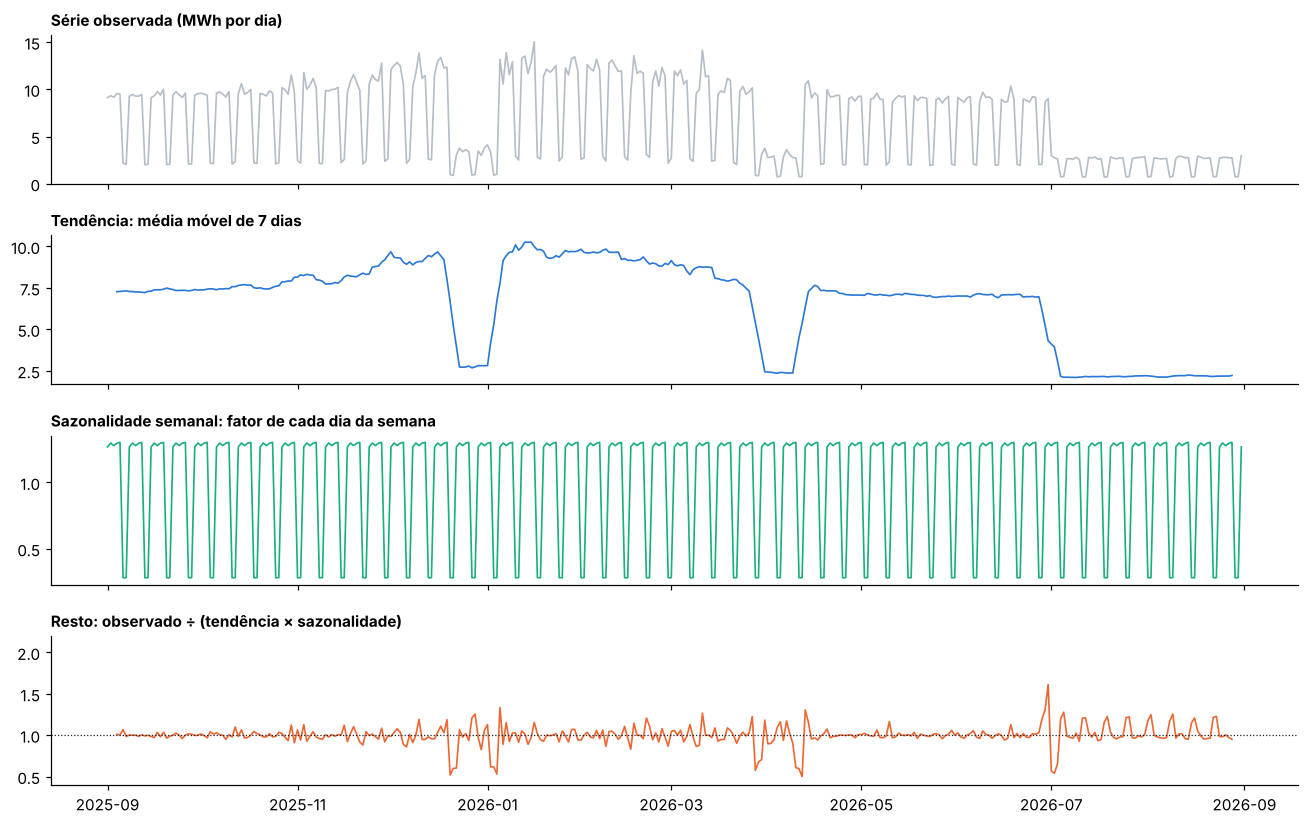

Fator de cada dia da semana (1,00 = igual à média da semana):
seg    1.27
ter    1.30
qua    1.28
qui    1.30
sex    1.30
sáb    0.28
dom    0.28


In [7]:
tendencia = serie.rolling(7, center=True).mean()
razao = serie / tendencia
nomes = ["seg", "ter", "qua", "qui", "sex", "sáb", "dom"]
em_aulas = ~meteo.set_index("data")["ferias"]
indice_semanal = razao[em_aulas].groupby(razao[em_aulas].index.dayofweek).median()
sazonalidade = pd.Series(serie.index.dayofweek.map(indice_semanal), index=serie.index)
resto = serie / (tendencia * sazonalidade)

fig, eixos = plt.subplots(4, 1, figsize=(12, 7.6), sharex=True)
for ax, valores, titulo, cor in zip(eixos, [serie, tendencia, sazonalidade, resto],
                                    ["Série observada (MWh por dia)", "Tendência: média móvel de 7 dias",
                                     "Sazonalidade semanal: fator de cada dia da semana", "Resto: observado ÷ (tendência × sazonalidade)"],
                                    [CINZA, AZUL, VERDE, LARANJA]):
    ax.plot(valores.index, valores, color=cor, lw=1.1)
    ax.set_title(titulo, fontsize=10)
eixos[3].axhline(1, color=TINTA, lw=0.8, ls=":")
eixos[3].set_ylim(0.4, 2.2)
plt.tight_layout()
plt.show()

print("Fator de cada dia da semana (1,00 = igual à média da semana):")
print(pd.Series(indice_semanal.values, index=nomes).round(2).to_string())

Lê os painéis de cima para baixo:

- a **tendência** sobe no inverno e tem três degraus bem marcados: Natal, Páscoa e o verão;
- a **sazonalidade** é o mesmo padrão de sete dias, repetido: os dias úteis ficam cerca de 30% acima da média da semana e os de fim de semana muito abaixo;
- o **resto** anda à volta de 1. Os picos são dias em que o consumo foi diferente do que a tendência e o dia da semana faziam esperar. Os maiores acontecem nas mudanças entre aulas e férias, onde a média móvel mistura os dois regimes, e nos dias de consumo anormal.

Esta decomposição é **multiplicativa** (as partes multiplicam-se), porque o efeito do fim de semana é proporcional ao nível: reduz o consumo para um quinto, seja inverno ou primavera. Quando o efeito é uma quantidade fixa, usa-se a forma aditiva (as partes somam-se).

## Autocorrelação: os dias não são independentes

Numa série temporal, os valores vizinhos parecem-se. A **autocorrelação** mede quanto: é a correlação da série com ela própria, deslocada um certo número de dias (o **desfasamento**).

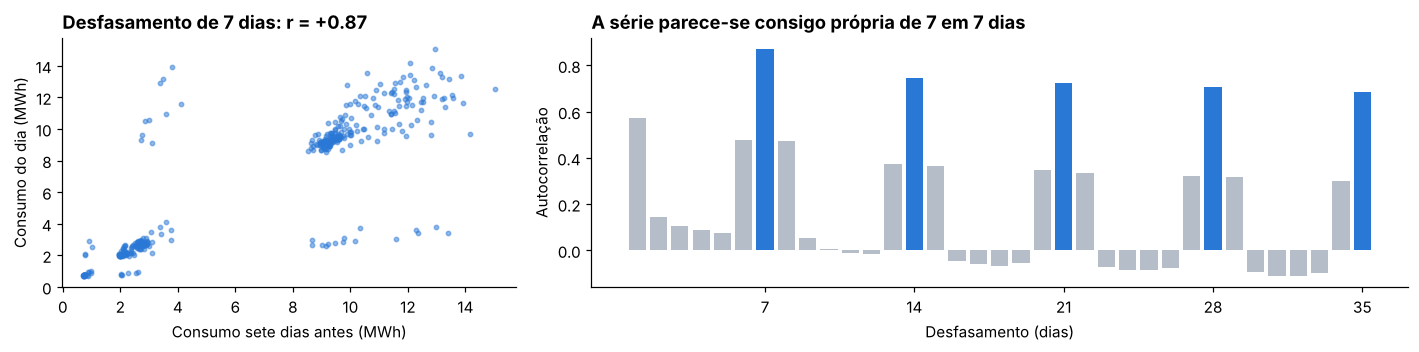

In [8]:
desfasamentos = range(1, 36)
auto = [serie.autocorr(k) for k in desfasamentos]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 3.3), gridspec_kw={"width_ratios": [1, 1.8]})
ax1.scatter(serie.shift(7), serie, s=8, color=AZUL, alpha=0.5)
ax1.set_xlabel("Consumo sete dias antes (MWh)")
ax1.set_ylabel("Consumo do dia (MWh)")
ax1.set_title(f"Desfasamento de 7 dias: r = {serie.autocorr(7):+.2f}")
ax2.bar(desfasamentos, auto, color=[AZUL if k % 7 == 0 else CINZA for k in desfasamentos])
ax2.set_xlabel("Desfasamento (dias)")
ax2.set_ylabel("Autocorrelação")
ax2.set_xticks(range(7, 36, 7))
ax2.set_title("A série parece-se consigo própria de 7 em 7 dias")
plt.tight_layout()
plt.show()

O gráfico da direita chama-se **correlograma**. Os picos aos 7, 14, 21 e 28 dias são a assinatura de um padrão semanal: uma segunda-feira parece-se com as outras segundas-feiras. Os valores baixos aos 2, 3 e 4 dias aparecem porque esses desfasamentos comparam muitas vezes um dia útil com um dia de fim de semana.

A autocorrelação tem três consequências práticas:

1. **Há menos informação do que parece.** 365 dias autocorrelacionados não valem 365 observações independentes. Os intervalos de confiança calculados como se o fossem ficam demasiado estreitos.
2. **Não se baralha o tempo.** Uma amostra aleatória de dias, ou uma divisão aleatória entre treino e teste, põe dias quase iguais dos dois lados e faz qualquer modelo parecer melhor do que é.
3. **O passado é uma variável.** O consumo de há sete dias é, por si só, uma boa previsão do de hoje.

## Variações

Muitas vezes interessa menos o nível do que a **mudança**.

| Medida | Cálculo | Em pandas |
| --- | --- | --- |
| Variação absoluta | valor de hoje − valor anterior | `serie.diff()` |
| Variação percentual | (hoje − anterior) ÷ anterior | `serie.pct_change()` |
| Em relação ao mesmo dia da semana anterior | os mesmos, com 7 dias de desfasamento | `serie.diff(7)`, `serie.pct_change(7)` |

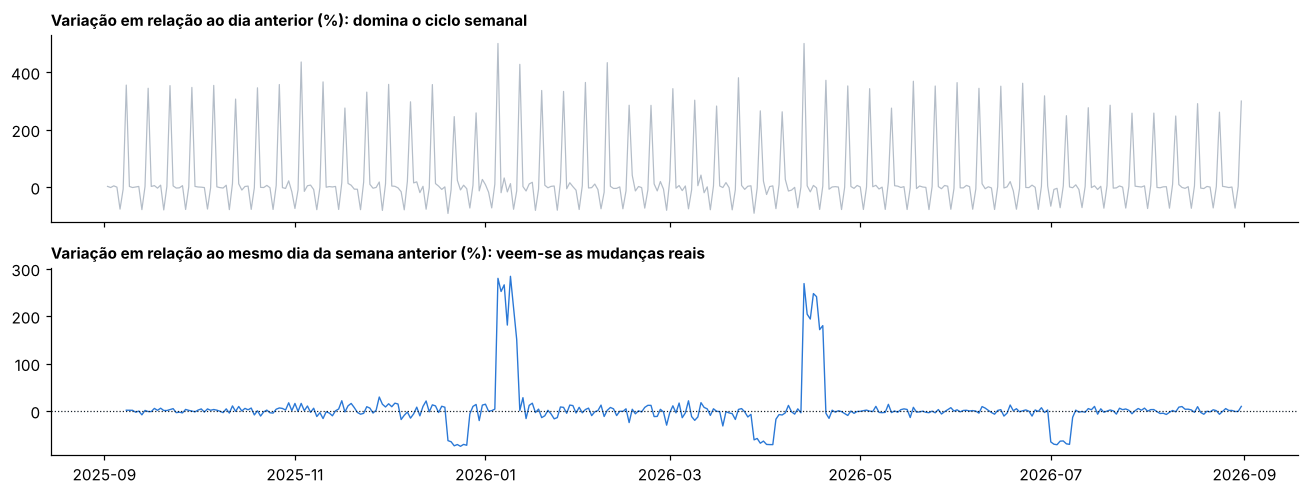

Desvio padrão da variação diária: 151 pontos percentuais
Desvio padrão da variação face à semana anterior: 48 pontos percentuais


In [9]:
de_ontem = serie.pct_change() * 100
da_semana_anterior = serie.pct_change(7) * 100

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 4.6), sharex=True)
ax1.plot(de_ontem.index, de_ontem.clip(-100, 500), color=CINZA, lw=0.8)
ax1.set_title("Variação em relação ao dia anterior (%): domina o ciclo semanal", fontsize=10)
ax2.plot(da_semana_anterior.index, da_semana_anterior.clip(-100, 300), color=AZUL, lw=0.9)
ax2.axhline(0, color=TINTA, lw=0.8, ls=":")
ax2.set_title("Variação em relação ao mesmo dia da semana anterior (%): veem-se as mudanças reais", fontsize=10)
plt.tight_layout()
plt.show()

print(f"Desvio padrão da variação diária: {de_ontem.std():.0f} pontos percentuais")
print(f"Desvio padrão da variação face à semana anterior: {da_semana_anterior.std():.0f} pontos percentuais")

A variação de um dia para o outro passa a vida a saltar: todas as segundas-feiras «sobe mais de 300%» e todos os sábados «cai quase 80%». Comparar com o mesmo dia da semana anterior tira esse efeito e deixa ver as mudanças verdadeiras: as entradas e as saídas de férias.

Comparar com o período homólogo (o mesmo dia da semana anterior, o mesmo mês do ano anterior) é a forma mais simples de descontar a sazonalidade.

A variação percentual tem uma armadilha: **não é simétrica**. Uma queda de 50% seguida de uma subida de 50% não volta ao ponto de partida (100 → 50 → 75). E quando o valor de partida é pequeno, qualquer mudança dá uma percentagem enorme.

## Prever sem modelo: as linhas de base

Antes de construir um modelo de previsão, convém saber quanto se consegue sem modelo nenhum (módulo 1, capítulo 3). Em séries temporais há três linhas de base clássicas.

| Linha de base | Previsão para amanhã |
| --- | --- |
| **Ingénua** | O valor de hoje |
| **Ingénua sazonal** | O valor do mesmo dia da semana anterior |
| **Média móvel** | A média dos últimos sete dias |

Para as comparar, respeitamos a ordem do tempo: tudo o que serve para prever um dia tem de ser anterior a esse dia. Avaliamos em maio e junho.

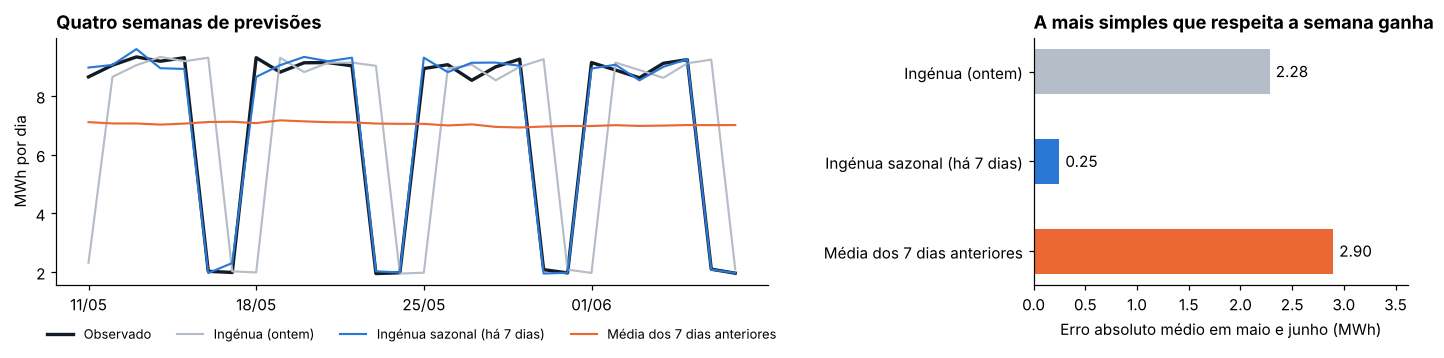

In [10]:
previsoes = pd.DataFrame({
    "Ingénua (ontem)": serie.shift(1),
    "Ingénua sazonal (há 7 dias)": serie.shift(7),
    "Média dos 7 dias anteriores": serie.shift(1).rolling(7).mean()})
teste = slice("2026-05-01", "2026-06-30")
erro = previsoes.loc[teste].sub(serie.loc[teste], axis=0).abs().mean()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 3.4), gridspec_kw={"width_ratios": [1.9, 1]})
exemplo = slice("2026-05-11", "2026-06-07")
ax1.plot(serie.loc[exemplo].index, serie.loc[exemplo], color=TINTA, lw=2.2, label="Observado")
for coluna, cor in zip(previsoes.columns, [CINZA, AZUL, LARANJA]):
    ax1.plot(previsoes.loc[exemplo].index, previsoes.loc[exemplo, coluna], color=cor, lw=1.4, label=coluna)
ax1.set_ylabel("MWh por dia")
ax1.set_title("Quatro semanas de previsões")
ax1.legend(frameon=False, fontsize=8.5, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.12))
ax1.set_xticks(pd.date_range("2026-05-11", "2026-06-07", freq="7D"), ["11/05", "18/05", "25/05", "01/06"])
barras = ax2.barh(erro.index, erro, color=[CINZA, AZUL, LARANJA], height=0.5)
ax2.bar_label(barras, fmt="%.2f", padding=4)
ax2.invert_yaxis()
ax2.set_xlim(0, erro.max() * 1.25)
ax2.set_xlabel("Erro absoluto médio em maio e junho (MWh)")
ax2.set_title("A mais simples que respeita a semana ganha")
plt.tight_layout()
plt.show()

- A previsão **ingénua** falha duas vezes por semana, e por muito: prevê para sábado o consumo de sexta, e para segunda o de domingo.
- A **média dos sete dias** nunca acerta: fica sempre a meio caminho entre os dias úteis e o fim de semana.
- A **ingénua sazonal** acompanha o padrão semanal e tem o menor erro.

O **erro absoluto médio** (MAE) é a média das distâncias entre a previsão e o observado, na unidade dos dados. Voltaremos às métricas no módulo 6.

Qualquer modelo que se construa para esta série tem de bater a ingénua sazonal. Se não bater, não vale a complexidade que acrescenta.

### Porque não se pode baralhar o tempo

Vamos avaliar a ingénua sazonal de duas maneiras, nos últimos meses do ano letivo. Em ambas, a previsão de um dia é o valor conhecido mais próximo com o mesmo dia da semana. Só muda a forma de escolher os dias de teste.

A divisão temporal treina até 2026-06-17 e testa a partir de 2026-06-18


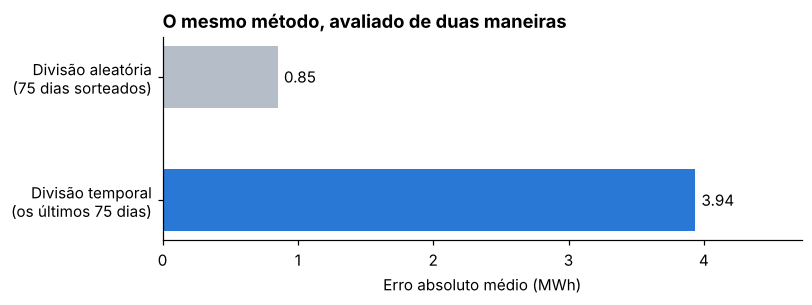

In [11]:
rng = np.random.default_rng(0)
posicoes = np.arange(len(serie))


def erro_mesmo_dia_da_semana(conhecidos, a_prever):
    """Prevê cada dia com o valor do dia conhecido mais próximo que calhe no mesmo dia da semana."""
    erros = []
    for p in a_prever:
        candidatos = conhecidos[(conhecidos - p) % 7 == 0]
        mais_proximo = candidatos[np.abs(candidatos - p).argmin()]
        erros.append(abs(serie.iloc[p] - serie.iloc[mais_proximo]))
    return np.mean(erros)


n_teste = 75
baralhado = rng.permutation(posicoes)
aleatorio = erro_mesmo_dia_da_semana(np.sort(baralhado[n_teste:]), baralhado[:n_teste])
corte = len(serie) - n_teste
temporal = erro_mesmo_dia_da_semana(posicoes[:corte], posicoes[corte:])
print(f"A divisão temporal treina até {serie.index[corte - 1].date()} e testa a partir de {serie.index[corte].date()}")

fig, ax = plt.subplots(figsize=(7.5, 2.4))
barras = ax.barh([f"Divisão aleatória\n({n_teste} dias sorteados)", f"Divisão temporal\n(os últimos {n_teste} dias)"], [aleatorio, temporal],
                 color=[CINZA, AZUL], height=0.5)
ax.bar_label(barras, fmt="%.2f", padding=4)
ax.invert_yaxis()
ax.set_xlim(0, max(aleatorio, temporal) * 1.2)
ax.set_xlabel("Erro absoluto médio (MWh)")
ax.set_title("O mesmo método, avaliado de duas maneiras")
plt.show()

O método é o mesmo e os erros são muito diferentes.

Com a divisão **aleatória**, cada dia de teste tem dias conhecidos na semana anterior e na seguinte. O erro é pequeno, e é uma ilusão: na prática, a semana seguinte nunca está disponível.

Com a divisão **temporal**, só se conhece o passado, e o passado acabou em junho, com as escolas a funcionar. Os dias a prever incluem as férias de verão, que o método não tinha como adivinhar. É este o erro que se teria na realidade.

A divisão aleatória escondeu duas coisas ao mesmo tempo: a fuga de informação do futuro e uma mudança de regime.

> **Em séries temporais, o teste vem sempre depois do treino.** Treina-se com o passado e avalia-se no futuro, como vai acontecer quando o modelo for usado.

## Cuidados com séries temporais

| Cuidado | Porquê |
| --- | --- |
| Confirmar que não faltam datas | Um dia em falta desloca todos os desfasamentos |
| Comparar com o período homólogo | Desconta a sazonalidade |
| Não correlacionar níveis de séries com tendência | Dá correlações espúrias (capítulo 5) |
| Usar só janelas para trás em tudo o que serve para prever | Uma janela centrada usa o futuro |
| Dividir treino e teste pelo tempo | A autocorrelação torna a divisão aleatória demasiado otimista |
| Desconfiar de mudanças de regime | Um padrão aprendido em tempo de aulas não serve nas férias |

## Exercícios

### `Exercício 1` – Que componente é?

Indica se cada efeito é tendência, sazonalidade ou resto:

1. As vendas de gelados sobem todos os verões.
2. O número de utilizadores de uma aplicação cresce 2% ao mês há três anos.
3. Numa terça-feira, um corte de energia fecha uma loja durante a tarde.
4. O trânsito numa ponte tem dois picos por dia, de manhã e ao fim da tarde.

<details>
<summary><b>Ver uma solução possível</b></summary>

1. Sazonalidade (período de um ano).
2. Tendência.
3. Resto.
4. Sazonalidade (período de um dia).

</details>

### `Exercício 2` – A série de uma escola

Constrói a série diária da escola `E03`. Calcula a média móvel de 7 dias **para trás** e desenha-a por cima da série. Em que dia o consumo se afastou mais dessa média, em percentagem?

In [12]:
# Escreve aqui o código do exercício 2

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
e03 = consumo[consumo["escola_id"] == "E03"].set_index("data")["kwh"]
media = e03.shift(1).rolling(7).mean()              # só com os sete dias anteriores
fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(e03.index, e03, color=CINZA, lw=0.8)
ax.plot(media.index, media, color=AZUL, lw=1.8)
plt.show()

mesmo_dia = e03.shift(7)
desvio = (e03 / mesmo_dia - 1) * 100
print(desvio.idxmax().date(), f"{desvio.max():.0f}% acima do mesmo dia da semana anterior")
```

Comparar com a média de sete dias mistura dias úteis e fins de semana. Comparar com o mesmo dia da semana anterior é mais justo. O maior desvio é um dos dias de consumo anormal, ou o primeiro dia de aulas depois de umas férias: os dois veem-se da mesma maneira, e só o calendário os distingue.

</details>

### `Exercício 3` – Autocorrelação sem o ciclo semanal

Calcula o correlograma da série **semanal** (total por semana), até 12 semanas de desfasamento. Os picos de 7 em 7 dias desapareceram? O que resta?

In [13]:
# Escreve aqui o código do exercício 3

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
semanal = serie.resample("W").sum()
auto_s = [semanal.autocorr(k) for k in range(1, 13)]
fig, ax = plt.subplots(figsize=(7, 2.8))
ax.bar(range(1, 13), auto_s, color=CINZA)
ax.set_xlabel("Desfasamento (semanas)")
plt.show()
```

O padrão semanal desapareceu, porque cada valor já é uma semana inteira. Resta uma autocorrelação alta que vai diminuindo devagar: semanas vizinhas são parecidas porque estão na mesma estação e no mesmo período letivo. É a assinatura de uma tendência.

</details>

### `Exercício 4` – Melhorar a linha de base

A ingénua sazonal falha na primeira semana depois de umas férias. Constrói uma previsão que use o valor de há 7 dias quando esse dia estava no mesmo regime (aulas ou férias) e o de há 14 dias caso contrário. Compara o erro com o da ingénua sazonal entre janeiro e junho.

In [14]:
# Escreve aqui o código do exercício 4

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
ferias = meteo.set_index("data")["ferias"]
mesmo_regime = ferias == ferias.shift(7)
melhorada = serie.shift(7).where(mesmo_regime, serie.shift(14))
periodo = slice("2026-01-01", "2026-06-30")
print("Ingénua sazonal:", round((serie.shift(7) - serie).abs().loc[periodo].mean(), 2))
print("Com regime:     ", round((melhorada - serie).abs().loc[periodo].mean(), 2))
```

O erro baixa, mas pouco: a seguir a duas semanas de férias, o dia de há 14 dias também estava em férias. Seria preciso recuar até à última semana de aulas. O calendário escolar é conhecido de antemão, por isso pode ser usado numa previsão sem fuga de informação.

</details>

## Verifica o que aprendeste

- [ ] Sei selecionar períodos numa série com índice de datas.
- [ ] Sei reamostrar uma série e explicar o que cada frequência mostra e esconde.
- [ ] Sei a diferença entre uma média móvel centrada e uma para trás.
- [ ] Sei descrever a tendência, a sazonalidade e o resto de uma série.
- [ ] Sei ler um correlograma.
- [ ] Sei três consequências da autocorrelação.
- [ ] Sei calcular variações e comparar com o período homólogo.
- [ ] Sei construir e avaliar linhas de base, respeitando a ordem do tempo.

## Leitura recomendada

- https://pandas.pydata.org/docs/user_guide/timeseries.html
- https://en.wikipedia.org/wiki/Time_series
- https://en.wikipedia.org/wiki/Autocorrelation
- https://en.wikipedia.org/wiki/Decomposition_of_time_series